# Task 3: Linear Regression

## AI & ML Internship – Elevate Labs

### Objective

To implement and understand Simple and Multiple Linear Regression using Scikit-learn.

### Dataset
Medical Insurance Cost Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
from google.colab import files
uploaded = files.upload()

Saving insurance.csv to insurance.csv


In [4]:
df = pd.read_csv('insurance.csv')
df.head()

,age,gender,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [6]:
print("Dataset Shape:", df.shape)
print("\nDataset Information:")
df.info()

Dataset Shape: (1338, 7)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   gender    1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


### Checking Missing Values

In [7]:
df.isnull().sum()

,0
age,0
gender,0
bmi,0
children,0
smoker,0
region,0
charges,0


### Checking Duplicate Records

In [8]:
df.duplicated().sum()

np.int64(1)

### Removing Duplicate Records

In [10]:
df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)
print("Duplicate Records:", df.duplicated().sum())

Dataset Shape After Removing Duplicates: (1337, 7)
Duplicate Records: 0


### Data Preprocessing

In [15]:
df = pd.get_dummies(df, columns=['gender', 'smoker', 'region'], drop_first=True, dtype=int)

df.head()

,age,bmi,children,charges,gender_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


### Splitting the Dataset

In [16]:
X = df.drop('charges', axis=1)
y = df['charges']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (1069, 8)
Testing Data Shape: (268, 8)


### Simple Linear Regression

In [17]:
X_simple = X[['age']]

X_train_simple, X_test_simple, y_train_simple, y_test_simple = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

simple_model = LinearRegression()
simple_model.fit(X_train_simple, y_train_simple)

print("Coefficient:", simple_model.coef_[0])
print("Intercept:", simple_model.intercept_)

Coefficient: 242.25815190122503
Intercept: 3534.0917330710636


### Simple Linear Regression Visualization

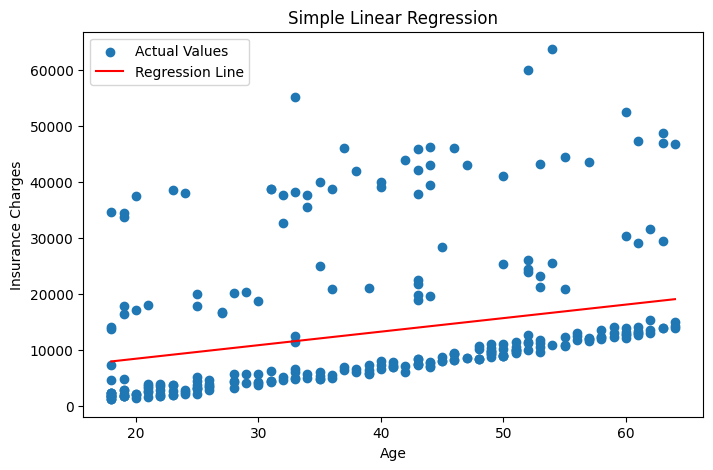

In [24]:
y_pred_simple = simple_model.predict(X_test_simple)

plot_data = X_test_simple.copy()
plot_data['predicted'] = y_pred_simple
plot_data = plot_data.sort_values('age')

plt.figure(figsize=(8, 5))
plt.scatter(X_test_simple['age'], y_test_simple, label='Actual Values')
plt.plot(plot_data['age'], plot_data['predicted'],
         color='red', label='Regression Line')
plt.xlabel('Age')
plt.ylabel('Insurance Charges')
plt.title('Simple Linear Regression')
plt.legend()
plt.show()

### Multiple Linear Regression

In [19]:
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

y_pred_multiple = multiple_model.predict(X_test)

print("Intercept:", multiple_model.intercept_)

print("\nCoefficients:")
for feature, coef in zip(X.columns, multiple_model.coef_):
    print(feature, ":", coef)

Intercept: -11092.65229594595

Coefficients:
age : 248.21072022470446
bmi : 318.70144095235077
children : 533.009988798697
gender_male : -101.54205399029631
smoker_yes : 23077.764592868083
region_northwest : -391.7614547836092
region_southeast : -838.9196157269652
region_southwest : -659.1397515529586


### Model Evaluation

In [20]:
mae = mean_absolute_error(y_test, y_pred_multiple)
mse = mean_squared_error(y_test, y_pred_multiple)
r2 = r2_score(y_test, y_pred_multiple)

print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("R2 Score:", r2)

Mean Absolute Error (MAE): 4177.045561036319
Mean Squared Error (MSE): 35478020.67523561
R2 Score: 0.8069287081198011


### Actual vs Predicted Values

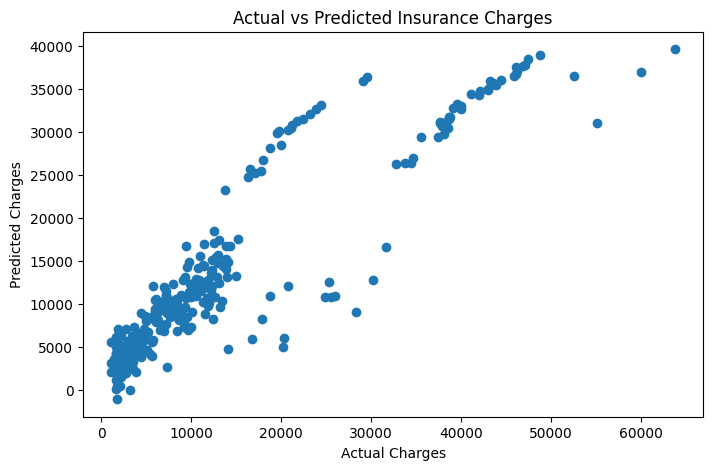

In [21]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred_multiple)
plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.title('Actual vs Predicted Insurance Charges')
plt.show()

### Observation

The Actual vs Predicted scatter plot shows the relationship between actual and predicted insurance charges. Points closer to the diagonal indicate more accurate predictions, while points farther away represent larger prediction errors. The model achieves an R² score of approximately 0.807, indicating that it explains about 80.69% of the variation in insurance charges.

### Simple Linear Regression Evaluation

In [22]:
mae_simple = mean_absolute_error(y_test_simple, y_pred_simple)
mse_simple = mean_squared_error(y_test_simple, y_pred_simple)
r2_simple = r2_score(y_test_simple, y_pred_simple)

print("Mean Absolute Error (MAE):", mae_simple)
print("Mean Squared Error (MSE):", mse_simple)
print("R2 Score:", r2_simple)

Mean Absolute Error (MAE): 9657.78934976123
Mean Squared Error (MSE): 166275348.23176482
R2 Score: 0.09513000782072023


### Comparison of Simple and Multiple Linear Regression

In [23]:
comparison = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'R2 Score'],
    'Simple Linear Regression': [mae_simple, mse_simple, r2_simple],
    'Multiple Linear Regression': [mae, mse, r2]
})

comparison

,Metric,Simple Linear Regression,Multiple Linear Regression
0,MAE,9.657789e+03,4.177046e+03
1,MSE,1.662753e+08,3.547802e+07
2,R2 Score,9.513001e-02,8.069287e-01


### Conclusion

- Simple Linear Regression achieved an R² score of 0.0951.
- Multiple Linear Regression achieved an R² score of 0.8069.
- Multiple Linear Regression performed better with lower MAE and MSE.
- Smoking status was an important predictor of medical insurance charges.
- This task helped in understanding regression models, data preprocessing, model evaluation, and coefficient interpretation.